In [1]:
from google.colab import files
uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")
print("Dimensões (linhas, colunas):", df.shape)
print("Valores ausentes:", df.isna().sum().sum())
df.head()

Dimensões (linhas, colunas): (284807, 31)
Valores ausentes: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print(df["Class"].value_counts())
print(f"Taxa de fraude: {df['Class'].mean() * 100:.3f}%")
print(f"Acurácia de um modelo que nunca marca fraude: {(df['Class'] == 0).mean() * 100:.2f}%")

Class
0    284315
1       492
Name: count, dtype: int64
Taxa de fraude: 0.173%
Acurácia de um modelo que nunca marca fraude: 99.83%


          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


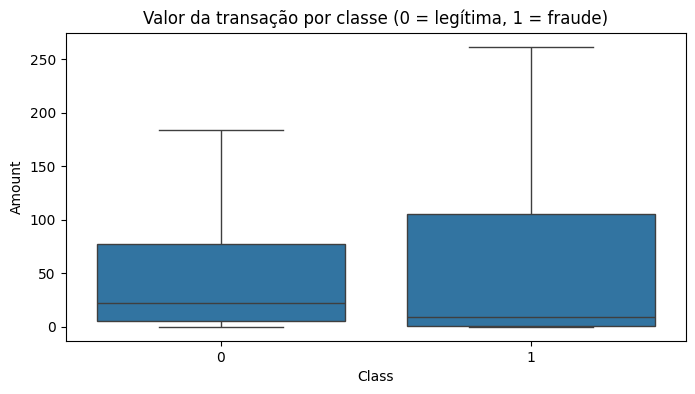

In [4]:
print(df.groupby("Class")["Amount"].describe())

plt.figure(figsize=(8, 4))
sns.boxplot(x="Class", y="Amount", data=df, showfliers=False)
plt.title("Valor da transação por classe (0 = legítima, 1 = fraude)")
plt.show()

In [5]:
correlacoes = df.corr()["Class"].drop("Class")
print(correlacoes.reindex(correlacoes.abs().sort_values(ascending=False).index).head(10))

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64
